# 05 · Sur-cotés et sous-cotés

Certains Pokémon sont populaires « pour des raisons évidentes » : c'est un starter, un légendaire, il vient de la première génération (nostalgie)… L'idée de ce notebook, c'est de **retirer ces effets attendus** pour voir ce qui reste.

Méthode : une **régression linéaire** (hors cours) de la popularité sur les effets attendus. Pour chaque Pokémon, le modèle donne une popularité « prévue ». Le **résidu** = popularité réelle − popularité prévue :
- résidu positif → le Pokémon est **plus populaire que prévu** (sur-coté) ;
- résidu négatif → **moins populaire que prévu** (sous-coté).

Comme on ne fusionne pas les sources (notebook 01), on fait **une régression par source** (Reddit, Johto Times, Google Trends) et on compare les résidus. Un Pokémon qui est sur-coté dans les trois sources, c'est beaucoup plus solide qu'un Pokémon sur-coté chez un seul public.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 50)
OUT = Path("../data/processed")
table = pd.read_csv(OUT / "table_maitre.csv", index_col="dex")
pop = pd.read_csv(OUT / "popularite_sources.csv", index_col="dex")
df = table.join(pop.drop(columns=["nom_fr", "generation"]))
df.shape

(1025, 47)

## 1. Quelle popularité expliquer ?

Pour chaque source on prend le **percentile** (décision du notebook 01) :
- **Reddit** : percentile global (809 Pokémon). Comme c'est global, on peut mettre la génération dans le modèle ;
- **Johto Times** : percentile **dans la génération**. Par construction, toutes les générations ont la même moyenne : l'effet génération est déjà retiré, on ne peut pas le mettre dans le modèle ;
- **Google Trends** : percentile médian sur les 67 pays gardés, sur tous les Pokémon (global). Depuis la deuxième collecte du notebook 02 (qui précise le bas du classement Google), ce sont toujours 67 pays, mais l'Allemagne est entrée et Trinité-et-Tobago est sortie. Dans le notebook 02, on a retiré de Google Trends les 28 Pokémon dont le nom anglais est aussi un mot courant (Persian, Durant/Fermite, Klink/Tic, Ditto/Métamorph, Electrode…) : leurs recherches parlaient surtout du mot, pas du Pokémon. Ils n'ont donc pas de valeur Google et la régression Google porte sur **997 Pokémon** au lieu de 1025 (ils restent bien sûr dans les deux sondages).

In [2]:
df["y_reddit"] = df["reddit_pct"]
df["y_johto"] = df["johto_pct_gen"]
df["y_trends"] = df["trends_pct_median"]
df[["y_reddit", "y_johto", "y_trends"]].describe()

,y_reddit,y_johto,y_trends
count,809.000000,1025.000000,997.000000
mean,0.500618,0.504390,0.499070
std,0.288797,0.288802,0.282047
min,0.003090,0.006410,0.002508
25%,0.254017,0.253205,0.251755
50%,0.493820,0.503704,0.499498
75%,0.749691,0.754967,0.738716
max,1.000000,1.000000,1.000000


Les trois percentiles vont de 0 à 1 avec une moyenne de 0,5, c'est normal pour des percentiles. Reddit n'a que 809 Pokémon, et Google Trends 997 à cause des 28 noms ambigus retirés.

### Ce qu'on a fait et pourquoi

**1. Le percentile comme popularité.** On a repris les percentiles du notebook 02 plutôt que les votes bruts. Les trois sources n'ont ni le même nombre de votants ni les mêmes unités, mais un percentile va toujours de 0 à 1 : on peut donc faire la même régression sur les trois et comparer les coefficients.

**2. Choisir le bon percentile pour chaque source.** Pour Reddit et Google, on a pris le percentile global, ce qui permet de mettre la génération dans le modèle. Pour le Johto Times, il n'existe que dans la génération, donc l'effet génération est déjà retiré et on ne peut pas le remettre. On a préféré garder ce que chaque source mesure vraiment plutôt que de forcer les trois dans le même moule.

## 2. Les effets attendus

On regarde d'abord chaque effet séparément, pour chaque source.

In [3]:
df["type_principal"] = df["type1"]
effets = ["generation", "stade_categorie", "starter", "legendaire", "fabuleux", "type_principal"]
for e in effets:
    print(df.groupby(e)[["y_reddit", "y_johto", "y_trends"]].mean().round(2).assign(n=df[e].value_counts()), "\n")

            y_reddit  y_johto  y_trends    n
generation                                  
1               0.67     0.50      0.74  151
2               0.62     0.51      0.58  100
3               0.51     0.50      0.52  135
4               0.54     0.50      0.56  107
5               0.37     0.50      0.39  156
6               0.41     0.51      0.51   72
7               0.32     0.51      0.46   88
8                NaN     0.51      0.39   96
9                NaN     0.50      0.34  120 

                 y_reddit  y_johto  y_trends    n
stade_categorie                                  
sans évolution       0.50     0.55      0.56  201
stade 1              0.41     0.39      0.52  340
stade 2              0.51     0.49      0.40  363
stade 3              0.72     0.79      0.64  121 

         y_reddit  y_johto  y_trends    n
starter                                  
False        0.48     0.49      0.49  944
True         0.70     0.70      0.61   81 

            y_reddit  y_johto  

Ce qu'on voit effet par effet :
- **génération** : sur Reddit et Google Trends, la génération 1 est nettement au-dessus et les générations récentes en dessous. C'est l'effet nostalgie qu'on attendait. Le Johto Times est à 0,5 partout, normal puisque c'est un percentile dans la génération ;
- **stade** : le stade 3 est le plus aimé dans les trois sources ;
- **starters** : 0,70 dans les deux sondages contre 0,48-0,49 pour les autres ;
- **légendaires** : ils sont **moins** bien classés que la moyenne sur Reddit (0,45), mais mieux au Johto Times (0,63) et sur Google ;
- **type** : Ténèbres, Spectre et Dragon sont en haut dans les sondages, Insecte et Roche en bas.

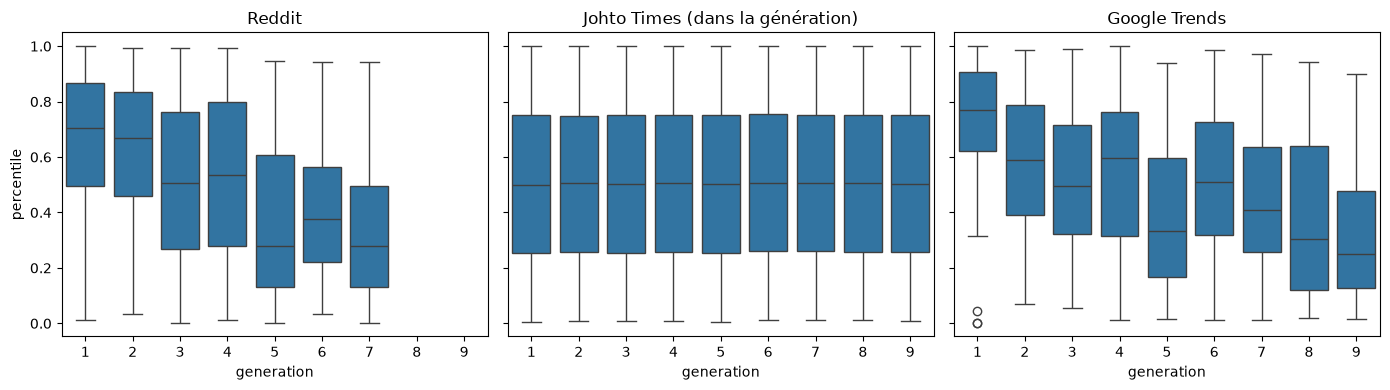

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, y, titre in zip(axes, ["y_reddit", "y_johto", "y_trends"], ["Reddit", "Johto Times (dans la génération)", "Google Trends"]):
    sns.boxplot(data=df, x="generation", y=y, ax=ax)
    ax.set_title(titre)
    ax.set_ylabel("percentile")
plt.tight_layout()
plt.show()

### Ce qu'on a fait et pourquoi

**1. Regarder chaque effet tout seul d'abord.** Avant la régression, on a fait la moyenne du percentile par génération, stade, starter, légendaire et type. C'est simple, et ça permet de vérifier que les effets qu'on va mettre dans le modèle existent vraiment, et dans quel sens.

**2. Les boxplots par génération.** On les a faits pour les trois sources côte à côte, avec le même axe vertical. Comme ça, on voit en un coup d'œil l'effet nostalgie sur Reddit et Google, et le fait que le Johto Times est plat par construction (percentile dans la génération). Le boxplot montre aussi l'étalement, pas seulement la moyenne : on voit qu'il y a des Pokémon très aimés dans toutes les générations.

## 3. Les régressions

On choisit comme variables explicatives les **effets « évidents »** qu'on retrouve dans l'axe ② du projet : génération (sauf pour le Johto Times, où elle est déjà retirée), catégorie de stade, starter, légendaire, fabuleux et type principal. On ne met volontairement **pas** le design (stats, taille, couleurs) : c'est justement ce qu'on veut retrouver dans ce qui reste.

Les variables qualitatives sont transformées en indicatrices (`C(...)`) avec une modalité de référence (génération 1, stade 1, type Normal). On utilise des erreurs standard robustes (HC3), parce que rien ne dit que la variance est la même pour tous les groupes.

In [5]:
base = "C(stade_categorie, Treatment('stade 1')) + starter + legendaire + fabuleux + C(type_principal, Treatment('normal'))"
formules = {
    "reddit": "y_reddit ~ C(generation) + " + base,
    "johto": "y_johto ~ " + base,
    "trends": "y_trends ~ C(generation) + " + base,
}
# Reddit ne couvre pas les générations 8 et 9 : on ne garde que les Pokémon qui ont une valeur dans la source
modeles = {s: smf.ols(f, data=df[df[f"y_{s}"].notna()]).fit(cov_type="HC3") for s, f in formules.items()}
pd.DataFrame({s: {"n": int(m.nobs), "R2": m.rsquared, "R2_ajuste": m.rsquared_adj} for s, m in modeles.items()}).round(3)

,reddit,johto,trends
n,809.000,1025.000,997.000
R2,0.379,0.256,0.408
R2_ajuste,0.356,0.239,0.389


Ce premier modèle explique environ **36 % de la variance sur Reddit, 24 % au Johto Times et 39 % sur Google Trends** (R² ajusté). Le Johto Times est plus bas en partie parce que l'effet génération n'est pas dans le modèle. Il reste donc la majorité de la popularité qui n'est pas expliquée par ces effets.

In [6]:
# les coefficients côte à côte (en points de percentile), avec une étoile si p < 0,05
def tab(m):
    return m.params.round(3).astype(str) + np.where(m.pvalues < 0.05, " *", "")
coefs = pd.DataFrame({s: tab(m) for s, m in modeles.items()})
coefs.index = coefs.index.str.replace("C(stade_categorie, Treatment('stade 1'))", "stade").str.replace("C(type_principal, Treatment('normal'))", "type").str.replace("C(generation)", "gen")
coefs.fillna("")

,reddit,johto,trends
gen[T.2],-0.056,,-0.18 *
gen[T.3],-0.183 *,,-0.242 *
gen[T.4],-0.17 *,,-0.223 *
gen[T.5],-0.338 *,,-0.383 *
gen[T.6],-0.299 *,,-0.294 *
gen[T.7],-0.381 *,,-0.342 *
gen[T.8],,,-0.413 *
gen[T.9],,,-0.451 *
stade[T.sans évolution],0.167 *,0.096 *,-0.017
stade[T.stade 2],0.1 *,0.104 *,-0.12 *


À autres effets égaux (en points de percentile) :
- chaque génération après la première fait perdre entre 6 et 45 points, de plus en plus pour les générations récentes ;
- le stade 3 fait gagner 28 points sur Reddit et 37 au Johto Times, mais seulement 9 sur Google ;
- être starter fait gagner 14 à 23 points ;
- être légendaire fait **perdre** 9 points sur Reddit, mais gagner 13 au Johto Times et 21 sur Google : les deux sondages ne sont pas d'accord sur les légendaires ;
- Ténèbres, Spectre, Dragon et Électrik sont significativement au-dessus de Normal dans les trois sources.

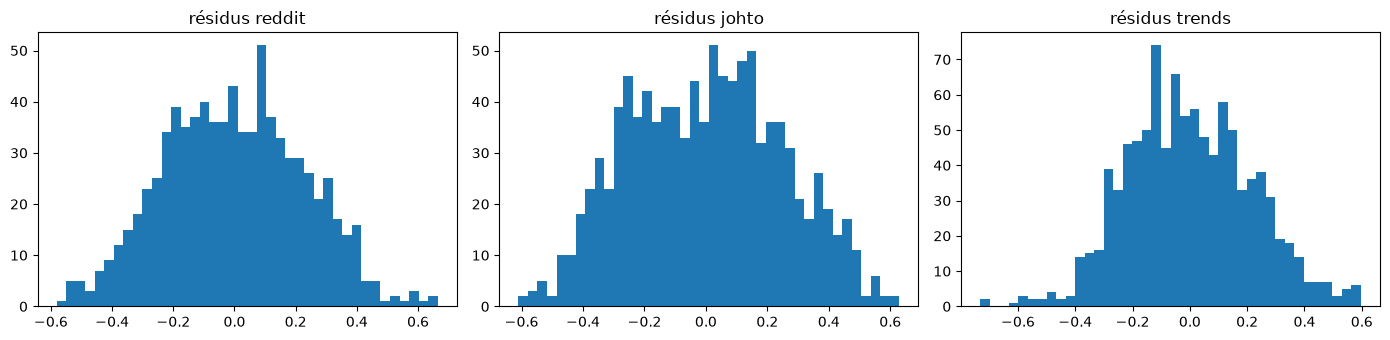

In [7]:
# les résidus : est-ce qu'ils ont l'air normaux ? (sinon les p-valeurs sont à prendre avec des pincettes)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (s, m) in zip(axes, modeles.items()):
    ax.hist(m.resid, bins=40)
    ax.set_title(f"résidus {s}")
plt.tight_layout()
plt.show()

### Le bonus starter est-il le même à tous les stades ?

Le modèle donne le même bonus « starter » à toute la lignée. Mais en pratique, on a l'impression que les fans aiment surtout le petit du début et la forme finale. On regarde la popularité moyenne des starters par stade.

In [8]:
df[df.starter].groupby("stade")[["y_reddit", "y_johto", "y_trends"]].mean().round(2)

,y_reddit,y_johto,y_trends
stade,,,
1,0.78,0.81,0.79
2,0.46,0.39,0.24
3,0.86,0.91,0.79


C'est très net : les starters de stade 1 sont autour de 0,8 et ceux de stade 3 entre 0,79 et 0,91, mais ceux de **stade 2 tombent entre 0,24 et 0,46**. L'étape du milieu est beaucoup moins aimée.

On essaie donc un modèle avec **un effet starter différent pour chaque stade** (une indicatrice starter × stade 1, starter × stade 2, starter × stade 3), et on compare.

In [9]:
for k in [1, 2, 3]:
    df[f"starter_s{k}"] = df["starter"] & (df["stade"] == k)
formules_inter = {s: f.replace("+ starter +", "+ starter_s1 + starter_s2 + starter_s3 +") for s, f in formules.items()}
modeles_inter = {s: smf.ols(f, data=df[df[f"y_{s}"].notna()]).fit(cov_type="HC3") for s, f in formules_inter.items()}
display(pd.DataFrame({s: {"R2 ajusté (un seul effet starter)": modeles[s].rsquared_adj, "R2 ajusté (effet starter par stade)": m.rsquared_adj}
                      for s, m in modeles_inter.items()}).round(3))
display(pd.DataFrame({s: tab(m).filter(like="starter") for s, m in modeles_inter.items()}))

,reddit,johto,trends
R2 ajusté (un seul effet starter),0.356,0.239,0.389
R2 ajusté (effet starter par stade),0.385,0.286,0.428


,reddit,johto,trends
starter_s1[T.True],0.454 *,0.473 *,0.332 *
starter_s2[T.True],-0.004,-0.097,-0.139 *
starter_s3[T.True],0.235 *,0.17 *,0.245 *


Avec un effet starter par stade, le R² ajusté monte dans les trois sources (de 0,239 à 0,286 au Johto Times par exemple). Un starter de stade 1 gagne 33 à 47 points, un starter de stade 3 gagne 17 à 25 points, et un starter de stade 2 ne gagne rien (il perd même 14 points sur Google).

**On garde donc ce deuxième modèle pour calculer les résidus.** Avec le premier, les starters de stade 2 seraient sortis « sous-cotés » juste parce que le modèle leur donnait à tort le même bonus qu'à toute la lignée. Ça aurait été un défaut du modèle, pas un vrai résultat.

### Ce qu'on a fait et pourquoi

**1. Une régression linéaire pour retirer les effets attendus (hors cours).** On voulait savoir ce qui reste de la popularité une fois qu'on a enlevé les raisons évidentes. La régression donne une popularité « prévue » pour chaque Pokémon, et le **résidu** (réel − prévu) dit s'il fait mieux ou moins bien que prévu. On a pris une régression linéaire parce qu'elle est simple à lire : chaque coefficient se lit directement en points de percentile.

**2. Des variables choisies exprès.** On n'a mis que les effets « évidents » (génération, stade, starter, légendaire, fabuleux, type) et volontairement **pas** le design (stats, taille, couleurs), parce que c'est justement ce qu'on veut retrouver dans les résidus. Si on l'avait mis, on l'aurait retiré nous-mêmes.

**3. Des indicatrices avec une modalité de référence.** Les variables qualitatives (génération, stade, type) sont transformées en indicatrices, avec une référence (génération 1, stade 1, Normal). Chaque coefficient se lit donc comme « par rapport à la référence ». On a choisi des références faciles à interpréter.

**4. Des erreurs standard robustes (HC3).** Rien ne dit que la popularité varie autant chez les légendaires que chez les Pokémon ordinaires. Avec HC3, les p-valeurs restent correctes même si la variance n'est pas la même partout, et les coefficients ne changent pas.

**5. Le R² ajusté.** On l'a utilisé pour comparer les modèles parce qu'il pénalise les variables en plus : sinon, ajouter des variables ferait toujours monter le R², même si elles ne servent à rien.

**6. L'histogramme des résidus.** On a regardé si les résidus ont une forme à peu près normale, parce que les p-valeurs de la régression reposent là-dessus. Un histogramme suffit pour repérer un gros problème (une forte asymétrie, deux bosses…).

**7. Un bonus starter par stade.** En regardant les starters par stade, on a vu que l'étape du milieu est beaucoup moins aimée que les deux autres. Le premier modèle donnait le même bonus à toute la lignée, donc il aurait classé les starters de stade 2 « sous-cotés » à cause d'un défaut du modèle. On a donc mis une indicatrice starter × stade, vérifié que le R² ajusté montait dans les trois sources, et gardé ce modèle.

## 4. Les résidus : qui est sur-coté, qui est sous-coté ?

In [10]:
res = pd.DataFrame({f"resid_{s}": m.resid for s, m in modeles_inter.items()})
res = df[["nom_fr", "generation", "type1", "stade_categorie", "starter", "legendaire"]].join(res)
res[["resid_reddit", "resid_johto", "resid_trends"]].corr(method="spearman").round(2)

,resid_reddit,resid_johto,resid_trends
resid_reddit,1.00,0.82,0.57
resid_johto,0.82,1.00,0.62
resid_trends,0.57,0.62,1.00


Les résidus des deux sondages se ressemblent beaucoup (0,82) : ce qui reste après avoir retiré les effets attendus est à peu près le même chez les deux publics. Google Trends suit moins (0,57-0,62).

In [11]:
cols = ["nom_fr", "generation", "type1", "stade_categorie", "resid_reddit", "resid_johto", "resid_trends"]
for s in ["reddit", "johto", "trends"]:
    print(f"=== {s} : les plus sur-cotés")
    display(res.sort_values(f"resid_{s}", ascending=False)[cols].head(10).round(2))
    print(f"=== {s} : les plus sous-cotés")
    display(res.sort_values(f"resid_{s}")[cols].head(10).round(2))

=== reddit : les plus sur-cotés


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
637,Pyrax,5,bug,stade 2,0.65,0.54,0.55
595,Statitik,5,bug,stade 1,0.63,0.58,0.27
700,Nymphali,6,fairy,stade 2,0.63,0.45,0.55
547,Farfaduvet,5,grass,stade 2,0.57,0.42,0.27
745,Lougaroc,7,rock,stade 2,0.57,0.52,0.57
596,Mygavolt,5,bug,stade 2,0.56,0.42,0.15
768,Sarmuraï,7,bug,stade 2,0.54,0.48,0.45
448,Lucario,4,fighting,stade 2,0.52,0.53,0.48
568,Miamiasme,5,poison,stade 1,0.51,0.35,-0.05


=== reddit : les plus sous-cotés


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
267,Charmillon,3,bug,stade 3,-0.58,-0.26,-0.19
247,Ymphect,2,rock,stade 2,-0.55,-0.43,0.11
489,Phione,4,water,sans évolution,-0.55,-0.56,-0.34
188,Floravol,2,grass,stade 2,-0.54,-0.37,-0.37
21,Piafabec,1,normal,stade 1,-0.52,-0.29,-0.18
102,Noeunoeuf,1,grass,stade 1,-0.51,-0.30,-0.17
372,Drackhaus,3,dragon,stade 2,-0.51,-0.54,-0.28
30,Nidorina,1,poison,stade 2,-0.50,-0.26,-0.16
118,Poissirène,1,water,stade 1,-0.50,-0.31,-0.19


=== johto : les plus sur-cotés


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
872,Frissonille,8,ice,stade 1,NaN,0.65,0.56
133,Évoli,1,normal,stade 1,0.44,0.65,0.28
194,Axoloto,2,water,stade 1,0.38,0.62,0.36
831,Moumouton,8,normal,stade 1,NaN,0.60,0.26
595,Statitik,5,bug,stade 1,0.63,0.58,0.27
363,Obalie,3,ice,stade 1,0.43,0.58,0.14
123,Insécateur,1,bug,stade 1,0.47,0.55,0.26
637,Pyrax,5,bug,stade 2,0.65,0.54,0.55
448,Lucario,4,fighting,stade 2,0.52,0.53,0.48


... (2 outputs left out)

=== trends : les plus sur-cotés


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
937,Malvalame,9,fire,stade 2,NaN,0.47,0.58
745,Lougaroc,7,rock,stade 2,0.57,0.52,0.57
571,Zoroark,5,dark,stade 2,0.32,0.39,0.57
900,Hachécateur,8,bug,stade 2,NaN,0.18,0.57
872,Frissonille,8,ice,stade 1,NaN,0.65,0.56
700,Nymphali,6,fairy,stade 2,0.63,0.45,0.55
637,Pyrax,5,bug,stade 2,0.65,0.54,0.55
471,Givrali,4,ice,stade 2,0.38,0.47,0.53
428,Lockpin,4,normal,stade 2,0.29,0.27,0.53


=== trends : les plus sous-cotés


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
32,Nidoran♂,1,poison,stade 1,-0.13,-0.12,-0.72
29,Nidoran♀,1,poison,stade 1,-0.34,-0.13,-0.71
122,M. Mime,1,psychic,stade 2,0.05,-0.13,-0.64
1003,Dinglu,9,dark,sans évolution,NaN,-0.46,-0.58
1001,Chongjian,9,dark,sans évolution,NaN,-0.20,-0.57
474,Porygon-Z,4,normal,stade 3,0.22,0.12,-0.57
1002,Baojian,9,dark,sans évolution,NaN,0.19,-0.56
1004,Yuyu,9,dark,sans évolution,NaN,0.02,-0.55
783,Écaïd,7,dragon,stade 2,-0.35,-0.55,-0.52


Quelques remarques sur les tops :
- côté **sur-cotés**, on retrouve des Pokémon que le modèle ne pouvait pas prévoir : Pyrax, Nymphali, Lucario, Lougaroc, Évoli, Axoloto… Les Insectes (Pyrax, Statitik, Mygavolt, Sarmuraï) ressortent beaucoup : le type est mal vu en moyenne, donc un Insecte réussi dépasse largement la prévision ;
- côté **sous-cotés**, il y a surtout des stades 2 et des Pokémon peu marquants (Charmillon, Floravol, Drackhaus…) ;
- sur **Google Trends**, maintenant que les noms ambigus sont retirés, le haut du classement ressemble à celui des sondages (Malvalame, Zoroark, Lougaroc, Pyrax, Nymphali, Frissonille, Givrali…). Par contre le bas vient encore beaucoup des noms : Nidoran♀/♂, M. Mime, Porygon-Z et les quatre Trésors du fléau (Chongjian, Baojian, Dinglu, Yuyu, en anglais *Wo-Chien*, *Chien-Pao*, *Ting-Lu*, *Chi-Yu*) ont des symboles, des points ou des tirets (et Flabébé des accents), donc les gens les tapent sûrement de plein de façons différentes et leurs recherches sont éparpillées. Les sous-cotés Google sont donc à lire avec prudence.

### Ce qu'on a fait et pourquoi

**1. Une régression par source.** On n'a pas fusionné les sources (décision du notebook 01), donc on a trois séries de résidus. Un Pokémon sur-coté dans les trois, c'est bien plus solide qu'un Pokémon sur-coté chez un seul public.

**2. Spearman entre les résidus.** Pour savoir si les trois sources « laissent » la même chose une fois les effets attendus retirés, on a comparé les résidus avec Spearman : on regarde si elles classent les Pokémon dans le même ordre, pas si les valeurs sont égales.

**3. Des tops 10 dans chaque sens.** Les tableaux des plus sur-cotés et des plus sous-cotés par source servent à lire les résultats Pokémon par Pokémon et à repérer les cas bizarres. C'est comme ça qu'on a vu que le bas de Google vient encore en partie de noms difficiles à taper (symboles, points, tirets).

## 5. Sur-coté partout, ou seulement quelque part ?

On garde la même logique que dans le notebook 02, pour que ce soit cohérent : dans chaque source, un Pokémon est « sur-coté » si son résidu est dans les **10 % les plus hauts**, et « sous-coté » s'il est dans les 10 % les plus bas.

In [12]:
SEUIL = 0.9
srcs = ["reddit", "johto", "trends"]
rangs = res[[f"resid_{s}" for s in srcs]].rank(pct=True)
dispo = rangs.notna().sum(axis=1)
sur = (rangs >= SEUIL).sum(axis=1)
sous = (rangs <= 1 - SEUIL).sum(axis=1)
res["sur_cote"] = np.select([(sur == dispo) & (dispo > 0), sur > 0], ["partout", "quelque part"], "non")
res["sous_cote"] = np.select([(sous == dispo) & (dispo > 0), sous > 0], ["partout", "quelque part"], "non")
print(res["sur_cote"].value_counts(), "\n")
print(res["sous_cote"].value_counts())

sur_cote
non             842
quelque part    144
partout          39
Name: count, dtype: int64 

sous_cote
non             829
quelque part    169
partout          27
Name: count, dtype: int64


Avec le seuil des 10 % : **39 Pokémon sont sur-cotés dans toutes les sources** et 27 sous-cotés partout (23 avant la deuxième collecte Google : Méios, Boustiflor, Serpang, Granbull et Hydragla sont entrés, Excavarenne est sorti).

Attention, « partout » veut dire « dans toutes les sources où le Pokémon a une valeur ». Pour les générations 8 et 9 (pas dans Reddit) et pour les noms ambigus (pas dans Google), ça ne fait que deux sources. C'est le cas de Galekid (sur-coté) et de Clic et Électrode (sous-cotés), qui sont jugés seulement sur les deux sondages.

In [13]:
print("Sur-cotés dans toutes les sources :")
display(res[res.sur_cote == "partout"][cols].sort_values("resid_johto", ascending=False).round(2))
print("Sous-cotés dans toutes les sources :")
display(res[res.sous_cote == "partout"][cols].sort_values("resid_johto").round(2))

Sur-cotés dans toutes les sources :


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
872,Frissonille,8,ice,stade 1,NaN,0.65,0.56
133,Évoli,1,normal,stade 1,0.44,0.65,0.28
194,Axoloto,2,water,stade 1,0.38,0.62,0.36
637,Pyrax,5,bug,stade 2,0.65,0.54,0.55
448,Lucario,4,fighting,stade 2,0.52,0.53,0.48
980,Terraiste,9,poison,stade 2,NaN,0.53,0.42
744,Rocabot,7,rock,stade 1,0.32,0.52,0.48
745,Lougaroc,7,rock,stade 2,0.57,0.52,0.57
840,Verpom,8,grass,stade 1,NaN,0.50,0.49


Sous-cotés dans toutes les sources :


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
489,Phione,4,water,sans évolution,-0.55,-0.56,-0.34
783,Écaïd,7,dragon,stade 2,-0.35,-0.55,-0.52
603,Lampéroie,5,electric,stade 2,-0.42,-0.55,-0.31
372,Drackhaus,3,dragon,stade 2,-0.51,-0.54,-0.28
1015,Fortusimia,9,poison,sans évolution,NaN,-0.48,-0.36
732,Piclairon,7,normal,stade 2,-0.29,-0.48,-0.28
1003,Dinglu,9,dark,sans évolution,NaN,-0.46,-0.58
611,Incisache,5,dragon,stade 2,-0.32,-0.46,-0.30
997,Cryodo,9,dragon,stade 2,NaN,-0.46,-0.33


Parmi les sur-cotés partout, on retrouve Évoli et 4 de ses évolutions (Phyllali, Givrali, Mentali, Nymphali), Lucario et Riolu, Rocabot et Lougaroc, Zorua. Parmi les sous-cotés partout, il y a beaucoup de **Dragons de stade 2** (Drackhaus, Écaïd, Incisache, Cryodo, Dispareptil) : ce sont les étapes intermédiaires de lignées dont la forme finale est très aimée, un peu comme les starters.

In [14]:
# sur-cotés dans les deux sondages mais pas sur Google (aimés plus que cherchés), et l'inverse
r_sond = (rangs["resid_reddit"] >= SEUIL) & (rangs["resid_johto"] >= SEUIL)
print("Sur-cotés dans les 2 sondages mais pas sur Google Trends :")
display(res[r_sond & (rangs["resid_trends"] < SEUIL)][cols].round(2))

Sur-cotés dans les 2 sondages mais pas sur Google Trends :


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
37,Goupix,1,fire,stade 1,0.41,0.50,0.14
38,Feunard,1,fire,stade 2,0.30,0.41,0.16
43,Mystherbe,1,grass,stade 1,0.36,0.33,0.08
54,Psykokwak,1,water,stade 1,0.41,0.48,0.24
58,Caninos,1,fire,stade 1,0.40,0.34,0.10
59,Arcanin,1,fire,stade 2,0.32,0.44,0.20
79,Ramoloss,1,water,stade 1,0.34,0.41,0.23
104,Osselait,1,ground,stade 1,0.33,0.39,0.12
123,Insécateur,1,bug,stade 1,0.47,0.55,0.26


29 Pokémon sont sur-cotés dans les deux sondages mais pas sur Google. Beaucoup viennent de la génération 1 (Goupix, Caninos, Arcanin, Psykokwak, Insécateur…) ou sont des stades 1 « mignons » (Skitty, Keunotor, Psystigri). Goupix est un bon exemple : très aimé (+0,50 au Johto Times), mais à peine plus cherché que ce que le modèle prévoit (+0,14 sur Google).

In [15]:
# est-ce que les sur/sous-cotés se concentrent dans certains groupes ?
for e in ["generation", "type1", "stade_categorie"]:
    t = pd.crosstab(res[e], res["sur_cote"] != "non", normalize="index")[True].rename("part_sur_cote")
    u = pd.crosstab(res[e], res["sous_cote"] != "non", normalize="index")[True].rename("part_sous_cote")
    display(pd.concat([t, u], axis=1).round(2).sort_values("part_sur_cote", ascending=False))

,part_sur_cote,part_sous_cote
generation,,
9,0.21,0.17
8,0.20,0.21
2,0.20,0.20
5,0.19,0.18
1,0.17,0.17
7,0.17,0.15
6,0.17,0.21
4,0.16,0.24
3,0.15,0.21


,part_sur_cote,part_sous_cote
type1,,
fairy,0.31,0.24
normal,0.22,0.25
poison,0.21,0.21
psychic,0.20,0.18
fighting,0.20,0.18
electric,0.20,0.19
grass,0.20,0.15
bug,0.18,0.19
dark,0.18,0.31


,part_sur_cote,part_sous_cote
stade_categorie,,
stade 2,0.21,0.24
stade 1,0.18,0.14
sans évolution,0.17,0.20
stade 3,0.08,0.17


En proportion, le type Fée a le plus de sur-cotés (31 %), et Ténèbres et Dragon le plus de sous-cotés (31 % et 27 %). C'est logique : le modèle prévoit déjà une popularité élevée pour ces types, donc un Dragon moyen tombe en dessous de la prévision. Le stade 3 a peu de sur-cotés (8 %) pour la même raison.

### Ce qu'on a fait et pourquoi

**1. Le même seuil que dans le notebook 02.** Un Pokémon est sur-coté si son résidu est dans les 10 % les plus hauts de la source, et sous-coté s'il est dans les 10 % les plus bas. On a repris la logique du notebook 02 (top 10 %, puis « partout / quelque part / non ») pour que les deux analyses se lisent pareil. Et on a passé les résidus en rang (percentile), parce qu'ils n'ont pas la même dispersion dans les trois sources.

**2. « Partout » = dans toutes les sources disponibles.** Les générations 8-9 n'ont pas Reddit, et les noms ambigus n'ont pas Google. On a choisi de les juger sur les sources qu'ils ont plutôt que de les exclure, en le disant clairement : leur « partout » ne repose que sur deux sources.

**3. Sondages contre Google.** On a sorti les Pokémon sur-cotés dans les deux sondages mais pas sur Google. C'est une façon directe de voir la différence entre être **aimé** (sondages) et être **cherché** (Google).

**4. Des tableaux croisés en proportion.** Pour voir si les sur/sous-cotés se concentrent dans certains groupes, on a calculé la **part** de sur-cotés et de sous-cotés dans chaque génération, type et stade. Les groupes n'ont pas la même taille, donc des comptes bruts auraient surtout montré les gros groupes.

## 6. Export

In [16]:
res.to_csv(OUT / "sur_sous_cotes.csv")
res.shape

(1025, 11)

In [17]:
# on exporte aussi les résultats intermédiaires pour pouvoir montrer la méthode dans le dashboard
lignes = []
for s in srcs:
    lignes.append({"source": s, "modele": "un bonus starter", "n": int(modeles[s].nobs), "r2_ajuste": modeles[s].rsquared_adj})
    lignes.append({"source": s, "modele": "bonus starter par stade", "n": int(modeles_inter[s].nobs), "r2_ajuste": modeles_inter[s].rsquared_adj})
pd.DataFrame(lignes).round(3).to_csv(OUT / "methode_05_modeles.csv", index=False)

# les coefficients du modèle gardé (starter par stade), avec des noms lisibles
types_fr = {"bug": "Insecte", "dark": "Ténèbres", "dragon": "Dragon", "electric": "Électrik", "fairy": "Fée",
            "fighting": "Combat", "fire": "Feu", "flying": "Vol", "ghost": "Spectre", "grass": "Plante",
            "ground": "Sol", "ice": "Glace", "poison": "Poison", "psychic": "Psy", "rock": "Roche",
            "steel": "Acier", "water": "Eau"}
def nom_lisible(v):
    if v == "Intercept":
        return "constante"
    if v.startswith("C(generation)"):
        return "génération " + v.split("[T.")[1].rstrip("]")
    if v.startswith("C(stade_categorie"):
        return v.split("[T.")[1].rstrip("]")
    if v.startswith("starter_s"):
        return "starter stade " + v[len("starter_s")]
    if v.startswith("legendaire"):
        return "légendaire"
    if v.startswith("fabuleux"):
        return "fabuleux"
    if v.startswith("C(type_principal"):
        return "type " + types_fr[v.split("[T.")[1].rstrip("]")]
    return v
coefs_export = pd.concat([pd.DataFrame({"source": s, "variable": [nom_lisible(v) for v in m.params.index],
                                        "coef": m.params.values, "p_valeur": m.pvalues.values})
                          for s, m in modeles_inter.items()], ignore_index=True)
coefs_export.round(4).to_csv(OUT / "methode_05_coefs.csv", index=False)
coefs_export.head(12)

,source,variable,coef,p_valeur
0,reddit,constante,0.549431,6.973345e-70
1,reddit,génération 2,-0.053797,6.245449e-02
2,reddit,génération 3,-0.181899,5.531162e-11
3,reddit,génération 4,-0.169995,6.682466e-09
4,reddit,génération 5,-0.336633,1.445916e-36
5,reddit,génération 6,-0.298531,1.720050e-19
6,reddit,génération 7,-0.380099,8.180165e-37
7,reddit,sans évolution,0.183937,5.772377e-12
8,reddit,stade 2,0.134216,1.609865e-10
9,reddit,stade 3,0.292610,1.459024e-24
